# **Load Data**

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

In [68]:
plt.style.use("ggplot")
sns.set_theme()

In [69]:
df = pd.read_csv("medical_insurance.csv", low_memory=False)

In [70]:
df

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,6266,50,Male,West,Urban,127200.0,No HS,Married,Employed,2,...,0,0,0,0,0,1,0,0,0,0
99996,54887,42,Male,East,Suburban,21600.0,HS,Married,Employed,2,...,0,0,0,0,0,0,0,0,0,0
99997,76821,41,Male,West,Rural,81900.0,HS,Divorced,Unemployed,1,...,0,0,0,1,0,1,0,0,0,0
99998,861,51,Female,South,Urban,43400.0,Doctorate,Single,Unemployed,3,...,0,0,1,0,0,2,2,1,0,0


In [71]:
df.columns.tolist()

['person_id',
 'age',
 'sex',
 'region',
 'urban_rural',
 'income',
 'education',
 'marital_status',
 'employment_status',
 'household_size',
 'dependents',
 'bmi',
 'smoker',
 'alcohol_freq',
 'visits_last_year',
 'hospitalizations_last_3yrs',
 'days_hospitalized_last_3yrs',
 'medication_count',
 'systolic_bp',
 'diastolic_bp',
 'ldl',
 'hba1c',
 'plan_type',
 'network_tier',
 'deductible',
 'copay',
 'policy_term_years',
 'policy_changes_last_2yrs',
 'provider_quality',
 'risk_score',
 'annual_medical_cost',
 'annual_premium',
 'monthly_premium',
 'claims_count',
 'avg_claim_amount',
 'total_claims_paid',
 'chronic_count',
 'hypertension',
 'diabetes',
 'asthma',
 'copd',
 'cardiovascular_disease',
 'cancer_history',
 'kidney_disease',
 'liver_disease',
 'arthritis',
 'mental_health',
 'proc_imaging_count',
 'proc_surgery_count',
 'proc_physio_count',
 'proc_consult_count',
 'proc_lab_count',
 'is_high_risk',
 'had_major_procedure']

## Handle Missing Value & Info

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 non-null  object 
 13  

In [73]:
df.describe()

,person_id,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
count,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,50000.500000,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,...,0.014770,0.108310,0.130140,0.508530,0.158690,0.508390,0.50933,0.509140,0.367810,0.169700
std,28867.657797,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,...,0.120632,0.310773,0.336459,0.749755,0.463562,0.747218,0.75363,0.750455,0.482212,0.375371
min,1.000000,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,25000.750000,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,50000.500000,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,75000.250000,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.00000,1.000000,1.000000,0.000000
max,100000.000000,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,...,1.000000,1.000000,1.000000,7.000000,6.000000,7.000000,7.00000,7.000000,1.000000,1.000000


In [74]:
df.isnull().sum()

,0
person_id,0
age,0
sex,0
region,0
urban_rural,0
income,0
education,0
marital_status,0
employment_status,0
household_size,0


In [75]:
# Cek jumlah missing value sebelum imputasi
print("Missing sebelum imputasi:", df['alcohol_freq'].isna().sum())

# Mengisi missing value dengan MODE (nilai yang paling sering muncul)
mode_alcohol = df['alcohol_freq'].mode()[0]
print("Mode alcohol_freq:", mode_alcohol)

df['alcohol_freq'] = df['alcohol_freq'].fillna(mode_alcohol)

# Cek kembali
print("Missing setelah imputasi:", df['alcohol_freq'].isna().sum())

Missing sebelum imputasi: 30083
Mode alcohol_freq: Occasional
Missing setelah imputasi: 0


In [76]:
df.isnull().sum()

,0
person_id,0
age,0
sex,0
region,0
urban_rural,0
income,0
education,0
marital_status,0
employment_status,0
household_size,0


## Check Duplicate Data

In [77]:
# Cek total baris duplikat
df.duplicated().sum()

np.int64(0)

#**FE**

Encode Categorical Features

In [78]:
# 1) Deteksi kolom kategorikal
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
print("Categorical columns detected:", cat_cols)

Categorical columns detected: ['sex', 'region', 'urban_rural', 'education', 'marital_status', 'employment_status', 'smoker', 'alcohol_freq', 'plan_type', 'network_tier']


In [79]:
# 2) ONE HOT ENCODING
df_ohe = pd.get_dummies(
    df,
    columns=cat_cols,     # kolom kategori
    drop_first=True,      # hindari multicollinearity
    dtype=int             # jadikan hasil encoding integer
)

print("\n=== ONE HOT ENCODING DONE ===")
print("Shape sebelum:", df.shape)
print("Shape setelah:", df_ohe.shape)

new_cols = [c for c in df_ohe.columns if c not in df.columns]
print(new_cols[:15], "...")   # tampilkan sebagian biar tidak kepanjangan


=== ONE HOT ENCODING DONE ===
Shape sebelum: (100000, 54)
Shape setelah: (100000, 73)
['sex_Male', 'sex_Other', 'region_East', 'region_North', 'region_South', 'region_West', 'urban_rural_Suburban', 'urban_rural_Urban', 'education_Doctorate', 'education_HS', 'education_Masters', 'education_No HS', 'education_Some College', 'marital_status_Married', 'marital_status_Single'] ...


In [80]:
df_ohe

,person_id,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,...,smoker_Former,smoker_Never,alcohol_freq_Occasional,alcohol_freq_Weekly,plan_type_HMO,plan_type_POS,plan_type_PPO,network_tier_Gold,network_tier_Platinum,network_tier_Silver
0,75722,52,22700.0,3,1,27.4,2,0,0,4,...,0,1,1,0,0,0,1,0,0,0
1,80185,79,12800.0,3,1,26.6,2,0,0,3,...,0,1,0,1,0,1,0,1,0,0
2,19865,68,40700.0,5,3,31.5,1,0,0,4,...,0,1,1,0,1,0,0,0,1,0
3,76700,15,15600.0,5,3,31.6,0,0,0,1,...,0,1,1,0,1,0,0,0,0,1
4,92992,53,89600.0,2,0,30.5,3,0,0,2,...,0,1,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,6266,50,127200.0,2,0,28.2,0,0,0,1,...,0,1,1,0,0,0,1,0,0,0
99996,54887,42,21600.0,2,0,27.6,0,0,0,1,...,0,1,1,0,0,0,1,0,0,1
99997,76821,41,81900.0,1,0,29.8,7,0,0,1,...,1,0,0,1,0,0,1,1,0,0
99998,861,51,43400.0,3,2,21.9,4,0,0,2,...,0,1,1,0,0,1,0,0,0,0


#**EDA**

## Korelasi antar fitur numerik (Heatmap)

In [81]:
# 1) Deteksi kolom numerik
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns detected:", numeric_cols)

Numeric columns detected: ['person_id', 'age', 'income', 'household_size', 'dependents', 'bmi', 'visits_last_year', 'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs', 'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c', 'deductible', 'copay', 'policy_term_years', 'policy_changes_last_2yrs', 'provider_quality', 'risk_score', 'annual_medical_cost', 'annual_premium', 'monthly_premium', 'claims_count', 'avg_claim_amount', 'total_claims_paid', 'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd', 'cardiovascular_disease', 'cancer_history', 'kidney_disease', 'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count', 'proc_surgery_count', 'proc_physio_count', 'proc_consult_count', 'proc_lab_count', 'is_high_risk', 'had_major_procedure']


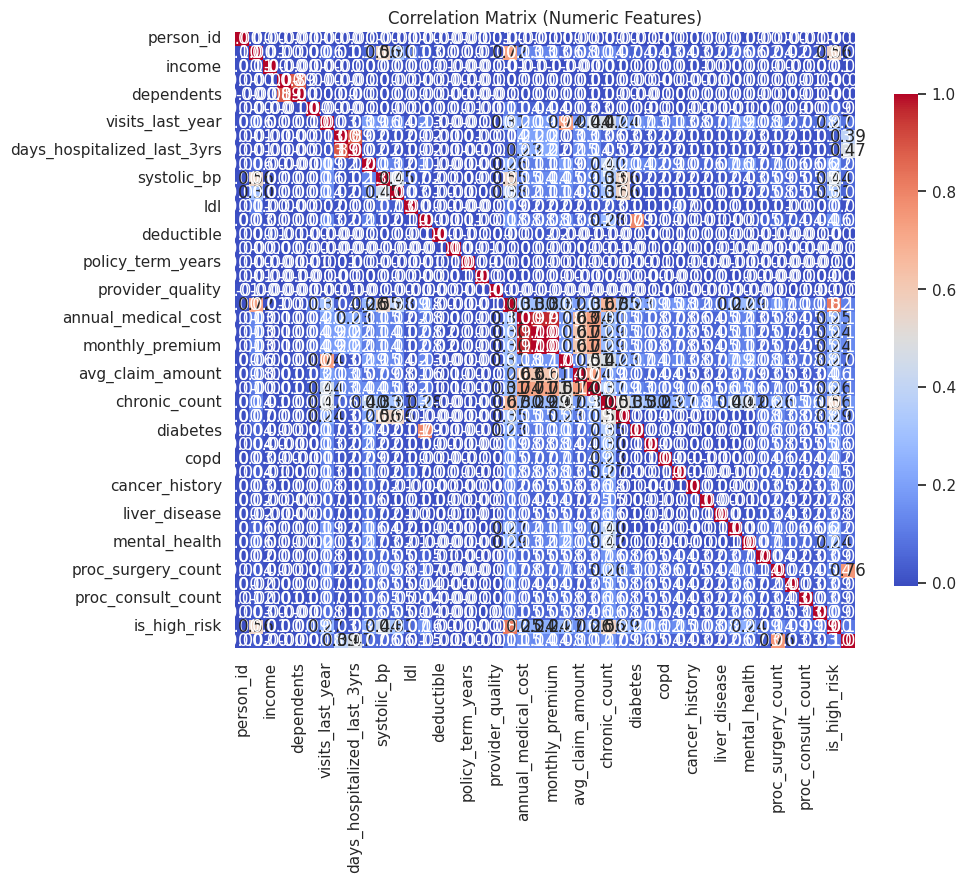

In [82]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={"shrink": .8})
plt.title("Correlation Matrix (Numeric Features)")
plt.show()

## Numerik vs target (Heatmap)


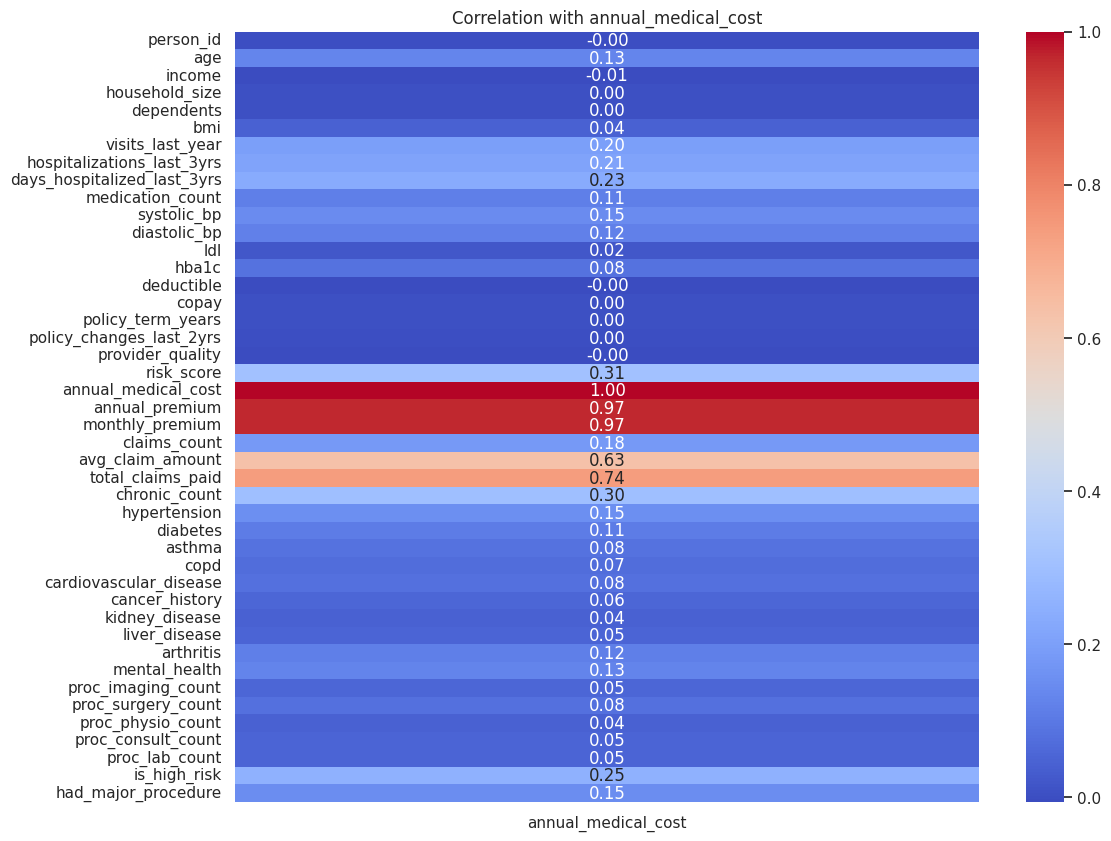

In [83]:
corr_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[corr_cols].corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr.loc[['annual_medical_cost']].T, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation with annual_medical_cost")
plt.show()

## Kategori vs target (Boxplot)

In [84]:
# Definisikan nama kolom target
target = "annual_medical_cost"

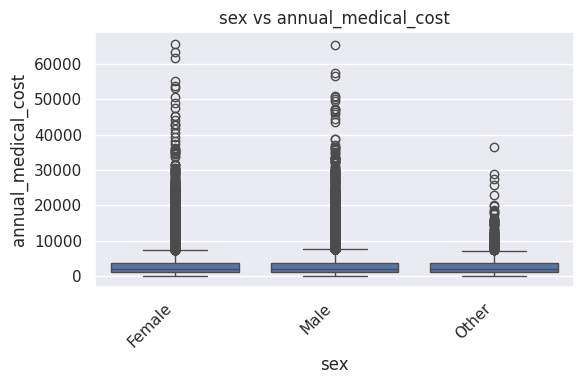

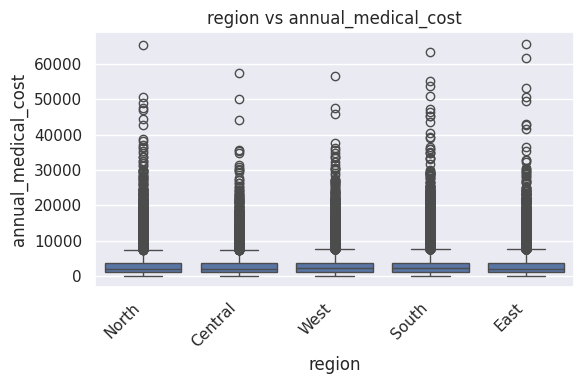

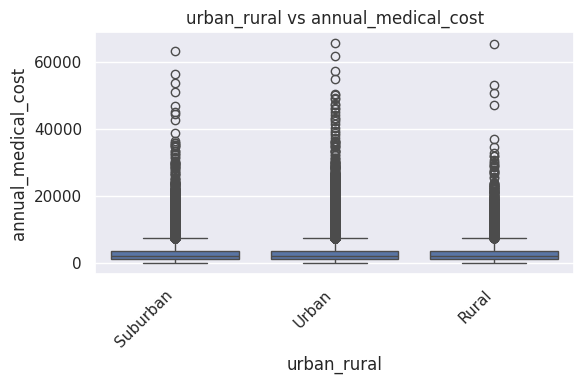

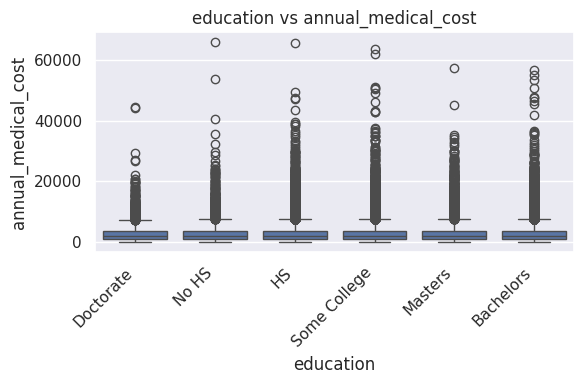

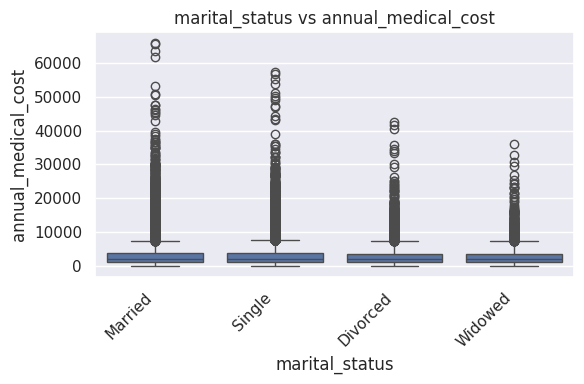

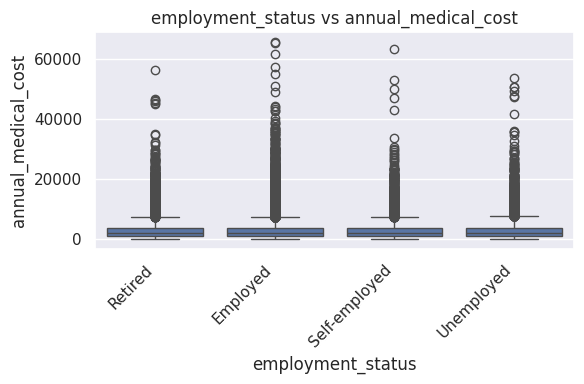

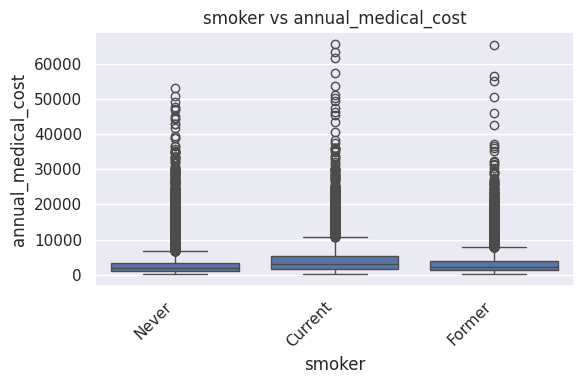

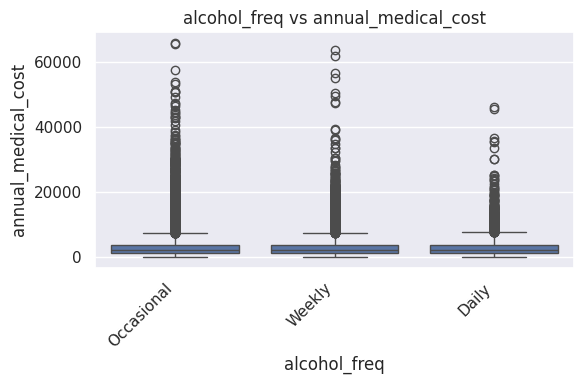

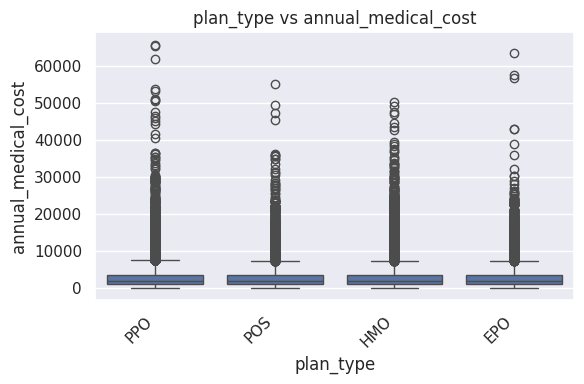

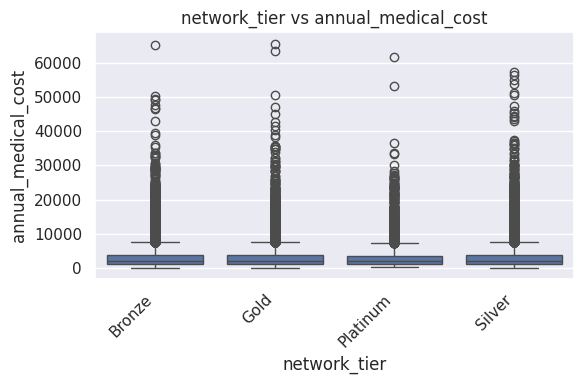

In [85]:
# B. Categorical vs Target (boxplot)
for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=col, y=target, data=df)
    plt.title(f"{col} vs {target}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#TRAIN–TEST SPLIT (REGRESSION ONLY)

Tujuan:

menjaga distribusi target antara train dan test

sangat membantu model ANN & Random Forest

mencegah test berisi range cost yang tidak muncul di train

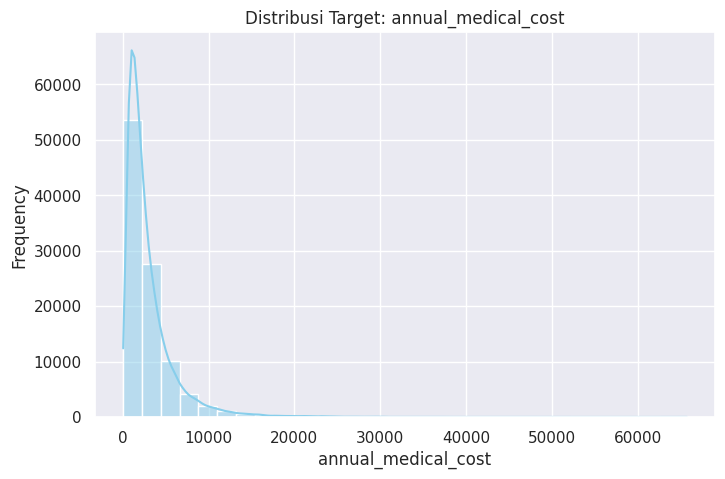

Skewness target: 4.030317894409436
Distribusi target sangat skewed → pertimbangkan stratify dengan binning


In [86]:
import seaborn as sns
import matplotlib.pyplot as plt

# Misal target = 'annual_medical_cost'
y = df['annual_medical_cost']

# 1. Visualisasi histogram + KDE
plt.figure(figsize=(8,5))
sns.histplot(y, bins=30, kde=True, color='skyblue')
plt.title("Distribusi Target: annual_medical_cost")
plt.xlabel("annual_medical_cost")
plt.ylabel("Frequency")
plt.show()

# 2. Statistik skewness
skewness = y.skew()
print("Skewness target:", skewness)

# Interpretasi sederhana
if abs(skewness) > 1:
    print("Distribusi target sangat skewed → pertimbangkan stratify dengan binning")
elif abs(skewness) > 0.5:
    print("Distribusi target cukup skewed → bisa dipertimbangkan stratify")
else:
    print("Distribusi target relatif normal → train_test_split biasa sudah cukup")


In [87]:
from sklearn.model_selection import train_test_split, StratifiedKFold
import pandas as pd
import numpy as np

In [88]:
# --- Data sudah bersih dan sudah handle outlier, encode dll ---
df_final = df_ohe.copy()  # ini buat menandai dataframe final

In [89]:
X = df_final.drop('annual_medical_cost', axis=1)
y = df_final['annual_medical_cost']

In [90]:
# 3. Stratified regression split menggunakan qcut binning
# -----------------------------
try:
    df_final["target_bin"] = pd.qcut(y, q=8, labels=False, duplicates="drop")

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    train_idx, test_idx = next(skf.split(X, df_final["target_bin"]))

    X_train = X.iloc[train_idx].reset_index(drop=True)
    X_test  = X.iloc[test_idx].reset_index(drop=True)
    y_train = y.iloc[train_idx].reset_index(drop=True)
    y_test  = y.iloc[test_idx].reset_index(drop=True)

    print("Stratified split berhasil.")
    print("Train:", X_train.shape, "| Test:", X_test.shape)

except Exception as e:
    print("Stratified gagal → fallback ke train_test_split biasa")
    print("Error:", e)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

Stratified split berhasil.
Train: (80000, 72) | Test: (20000, 72)


In [91]:
print("=== SIZE CHECK ===")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)


=== SIZE CHECK ===
X_train: (80000, 72)
y_train: (80000,)
X_test : (20000, 72)
y_test : (20000,)


#Balanced/Imbalanced

In [92]:
plt.style.use("ggplot")
sns.set_theme()

print("=== Target Summary (Train Set) ===")
print(y_train.describe())
print("\nSkewness:", skew(y_train))

=== Target Summary (Train Set) ===
count    80000.000000
mean      3007.262396
std       3120.512203
min         55.550000
25%       1175.115000
50%       2082.575000
75%       3707.957500
max      65724.900000
Name: annual_medical_cost, dtype: float64

Skewness: 4.071585079524483


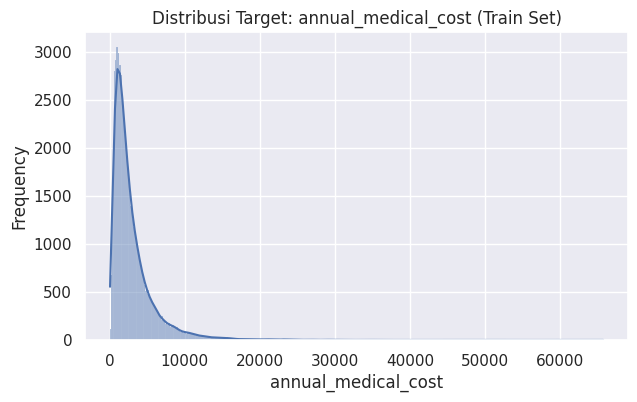

In [93]:
# VISUALISASI DISTRIBUSI TARGET DI TRAIN SET
# --------------------------------------------------------
plt.figure(figsize=(7,4))
sns.histplot(y_train, kde=True)
plt.title("Distribusi Target: annual_medical_cost (Train Set)")
plt.xlabel("annual_medical_cost")
plt.ylabel("Frequency")
plt.show()

In [94]:
# CEK APAKAH “IMBALANCED” BERDASARKAN SKEWNESS
# (regression imbalance = skewness tinggi)
# --------------------------------------------------------

sk = skew(y_train)

if sk > 1:
    print("\n⚠ PERINGATAN: Target sangat right-skewed → nilai tinggi jauh lebih banyak.")
    print("   Disarankan: log-transform sebelum training (untuk ANN / Linear model).")

elif sk > 0.5:
    print("\n⚠ Moderately skewed → mungkin perlu transformasi log pada beberapa model.")
else:
    print("\n✔ Distribusi target relatif seimbang & normal.")


⚠ PERINGATAN: Target sangat right-skewed → nilai tinggi jauh lebih banyak.
   Disarankan: log-transform sebelum training (untuk ANN / Linear model).


#**Scaling**

Tujuan Scaling:

Menyamakan skala seluruh fitur numerik

Menghindari dominance fitur besar (income, annual_premium)

Membantu model ANN/Regressor belajar lebih stabil

Umumnya fitur numerik → StandardScaler, kategori → tidak di-scale

In [95]:
df_final = df_ohe.copy()

In [96]:
# Buang kolom ID dari X_train dan X_test
if "person_id" in X_train.columns:
    X_train = X_train.drop("person_id", axis=1)
    X_test = X_test.drop("person_id", axis=1)

In [97]:
# Ambil kolom numerik dari X_train
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

In [98]:
 from sklearn.preprocessing import StandardScaler

In [99]:
scaler = StandardScaler()

In [100]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

In [101]:
# FIT hanya pada TRAIN
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# TRANSFORM pada TEST
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Scaling Completed")

Scaling Completed


In [102]:
print(X_train)
print("Scaling Completed")

       age    income  household_size  dependents   bmi  visits_last_year  \
0       79   12800.0               3           1  26.6                 2   
1       68   40700.0               5           3  31.5                 1   
2       53   89600.0               2           0  30.5                 3   
3       63  305000.0               3           2  20.4                 1   
4       36   38900.0               1           0  21.6                 0   
...    ...       ...             ...         ...   ...               ...   
79995   37  108700.0               1           0  25.5                 1   
79996   50  127200.0               2           0  28.2                 0   
79997   42   21600.0               2           0  27.6                 0   
79998   41   81900.0               1           0  29.8                 7   
79999   51   43400.0               3           2  21.9                 4   

       hospitalizations_last_3yrs  days_hospitalized_last_3yrs  \
0                    

In [103]:
print(X_test)
print("Scaling Completed")

       age    income  household_size  dependents   bmi  visits_last_year  \
0       52   22700.0               3           1  27.4                 2   
1       15   15600.0               5           3  31.6                 0   
2       59   61900.0               2           0  24.1                 3   
3       54   76400.0               2           0  25.5                 2   
4       45  201300.0               2           1  39.1                 3   
...    ...       ...             ...         ...   ...               ...   
19995   50   20500.0               4           3  23.2                 3   
19996   63   11200.0               3           1  23.5                 1   
19997   54    8500.0               3           2  24.9                 4   
19998   76   50600.0               2           1  27.2                 5   
19999   44   43700.0               2           0  29.2                 1   

       hospitalizations_last_3yrs  days_hospitalized_last_3yrs  \
0                    

#**Hyperparameter Tuning**

##1. Linear Regression

Linear Regression tidak perlu hyperparameter tuning, jadi langsung training & evaluasi.

##2. Random Forest

Untuk Random Forest, kamu tidak perlu scaling sama sekali. Jadi kode kamu sudah benar: pakai X_train dan X_test asli (tanpa _scaled).

In [104]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# ===============================
# 1) SUBSET untuk tuning (lebih cepat)
# ===============================
subset_size = 10000  # bebas diganti (5k, 15k, dll)
X_sub = X_train.sample(subset_size, random_state=42)
y_sub = y_train.loc[X_sub.index]

# ===============================
# 2) Parameter Grid
# ===============================
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf = RandomForestRegressor(random_state=42)

# ===============================
# 3) RandomizedSearchCV
# ===============================
rand_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

rand_rf.fit(X_sub, y_sub)

print("\n=== Best Hyperparameters RF ===")
print(rand_rf.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits

=== Best Hyperparameters RF ===
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}


##3. ANN

In [105]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import RandomizedSearchCV

# ===============================
# 1) SUBSET TUNING dari TRAIN yang sudah SCALE
# ===============================
subset_size = min(5000, len(X_train))
X_sub = X_train[:subset_size]  # pastikan ini X_train_scaled
y_sub = y_train[:subset_size]

# ===============================
# 2) Parameter grid ANN
# ===============================
param_grid_ann = {
    'hidden_layer_sizes': [(64,), (64,64), (128,64)],
    'activation': ['relu', 'tanh'],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [500, 1000]
}

ann = MLPRegressor(random_state=42)

# ===============================
# 3) RandomizedSearchCV
# ===============================
rand_ann = RandomizedSearchCV(
    estimator=ann,
    param_distributions=param_grid_ann,
    n_iter=10,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit pada subset training yang sudah scaled
rand_ann.fit(X_sub, y_sub)

print("\n=== Best Hyperparameters ANN ===")
print(rand_ann.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

=== Best Hyperparameters ANN ===
{'max_iter': 500, 'learning_rate_init': 0.001, 'hidden_layer_sizes': (64,), 'activation': 'relu'}


#**Retrain Final Model**

##1. Linear Regression

Retrain Full Train (tanpa tuning)

In [106]:
from sklearn.linear_model import LinearRegression

# Train model on full train data
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# Predict
y_pred_lin = lin_reg.predict(X_test_scaled)


##2. Random Forest

In [107]:
# Dapatkan best hyperparameters dari tuning
best_rf_params = rand_rf.best_params_

# Buat model baru dengan best params
final_rf = RandomForestRegressor(
    **best_rf_params,
    random_state=42
)

# Train di seluruh X_train & y_train
final_rf.fit(X_train, y_train)

# Predict di TEST SET
y_pred_rf = final_rf.predict(X_test)

##3. ANN

In [108]:
# Ambil best params
best_ann_params = rand_ann.best_params_

# Buat model ANN baru
final_ann = MLPRegressor(**best_ann_params, random_state=42)

# Fit pada full train data yang sudah scaled
final_ann.fit(X_train, y_train)

# Predict menggunakan X_test_scaled
y_pred_ann = final_ann.predict(X_test)

# **Evaluasi**

## 1. Linier Regression

In [109]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1) Evaluasi performa
r2_lin = r2_score(y_test, y_pred_lin)
mae_lin = mean_absolute_error(y_test, y_pred_lin)
rmse_lin = mean_squared_error(y_test, y_pred_lin)**0.5

print("Linear Regression Performance:")
print("R2 Score:", r2_lin)
print("MAE:", mae_lin)
print("RMSE:", rmse_lin)


Linear Regression Performance:
R2 Score: 0.9656670370855777
MAE: 319.842918852775
RMSE: 584.6127853456495


## 2. Random Forest

In [110]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# 1) Evaluasi performa Random Forest
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("=== Random Forest Performance ===")
print("R2 Score:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

=== Random Forest Performance ===
R2 Score: 0.9980056680928195
MAE: 7.0948726427377276
RMSE: 140.90012734492151


## 3. ANN

In [111]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# RMSE
rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_ann))
# MAE
mae_ann = mean_absolute_error(y_test, y_pred_ann)
# R2
r2_ann = r2_score(y_test, y_pred_ann)

print("=== ANN Evaluation ===")
print(f"RMSE : {rmse_ann}")
print(f"MAE  : {mae_ann}")
print(f"R2   : {r2_ann}")


=== ANN Evaluation ===
RMSE : 384.68227982182793
MAE  : 194.3880305812629
R2   : 0.9851345168570369


#**Perbandigan Model**

In [112]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "ANN"],
    "R2": [r2_lin, r2_rf, r2_ann],
    "MAE": [mae_lin, mae_rf, mae_ann],
    "RMSE": [rmse_lin, rmse_rf, rmse_ann]
})

print("=== Model Comparison ===")
print(results)


=== Model Comparison ===
               Model        R2         MAE        RMSE
0  Linear Regression  0.965667  319.842919  584.612785
1      Random Forest  0.998006    7.094873  140.900127
2                ANN  0.985135  194.388031  384.682280
